# 02 · Zadanie I1: wyrocznia `cpsam` na CAMELYON17 (segmentacja jąder)

Odpowiednik notebooka 02 dla MoNuSeg. **Różnica kluczowa: CAMELYON17 nie ma masek jąder**, są tylko obrysy
zmian przerzutowych (XML). Dlatego nie liczymy PQ względem ground truth. Zamiast tego:

1. **Kafle:** tniemy zaadnotowane slajdy (notebook 01) na kafle 1000×1000 px (jak w MoNuSeg), po `per_group` kafli
   „guz” i „normalna” z każdego slajdu. Maski guza z XML służą tylko do stratyfikacji.
2. **A, wyrocznia `cpsam`:** zamrożona, „adnotuje” jądra na kaflach. Jej maski są wszystkim, co student zobaczy w I3.
3. **B, niewytrenowany Cellpose-SAM** (encoder SAM + losowa głowica, seed 0): oczekujemy, że nie znajdzie jąder.
4. **Charakterystyka wyroczni:** liczba i rozmiar jąder na kafel (ośrodki, guz vs normalna) oraz **samozgodność**:
   PQ między maską kafla a maską jego lustrzanego odbicia. To szacuje szum samej wyroczni i wyznacza
   poprzeczkę dla studenta w notebooku 03.

**Ograniczenia, o których trzeba pamiętać:**
- Wszystkie liczby tu to *zgodność z wyrocznią* albo statystyki jej wyjścia, a nie dokładność względem patologa.
- W odróżnieniu od MoNuSeg nie wiem, czy CAMELYON17 był w danych treningowych Cellpose-SAM. Sprawdź to w pracy
  Pachitariu i in. 2025, zanim napiszesz, że wyniki są niezależne.
- Wyrocznia mogła nigdy nie widzieć węzłów chłonnych barwionych w tych ośrodkach (inne barwienie niż TCGA).
  Jakość jej masek bywa tu niższa niż na MoNuSeg, a nie ma GT, żeby to zmierzyć. Obejrzyj wizualizacje.

Kod: `datasets/camelyon17.py`, `al/camelyon17_random_loop.py`. Uruchamiaj na GPU.

In [1]:
# --- działa bez instalacji pakietu: dodaje src/ repo do ścieżki importu ---
import sys
from pathlib import Path

_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "histopathology_pnw").exists())
sys.path.insert(0, str(_root / "src"))

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cellpose import io as cp_io
from skimage.measure import regionprops_table
from skimage.segmentation import find_boundaries

from histopathology_pnw.al import camelyon17_random_loop as al
from histopathology_pnw.config import Settings
from histopathology_pnw.datasets import camelyon17 as c17
from histopathology_pnw.device import get_device
from histopathology_pnw.inference import EVAL_KWARGS, predict
from histopathology_pnw.metrics import evaluate_all, summarize
from histopathology_pnw.models.oracle import load_oracle
from histopathology_pnw.models.student import build_student_init, load_student

cp_io.logger_setup()
device = get_device()
MODE = os.environ.get("AL_MODE", "smoke")  # "smoke" albo "full"
PER_GROUP = 4  # kafli "guz" i "normalna" z każdego slajdu (to samo w smoke i full, żeby nie wycinać od nowa)
out_dir = Settings().outputs_dir / "i1_c17"
out_dir.mkdir(parents=True, exist_ok=True)
print("device:", device, "| MODE:", MODE, "| wyniki:", out_dir)
EVAL_KWARGS

[GUI INFO] : WRITING LOG OUTPUT TO /home/alehen0076/.cellpose/run.log

cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.17 
torch version:  	2.14.1+cu130
2026-10-26 19:55:08,007 [io INFO] WRITING LOG OUTPUT TO /home/alehen0076/.cellpose/run.log


2026-10-26 19:55:08,007 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.17 
torch version:  	2.14.1+cu130


device: cpu | MODE: smoke | wyniki: /home/alehen0076/histopathology_pnw/outputs/i1_c17


/home/alehen0076/histopathology_pnw/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'channel_axis': -1,
 'diameter': None,
 'flow_threshold': 0.4,
 'cellprob_threshold': 0.0}

## 1. Kafle

Slajdy z podziału z notebooka 01 (train / val / test po pacjencie; test wydzielany raz w `configs/camelyon17_split.json`).
Z każdego slajdu losujemy kafle tylko z gęstą tkanką (≥ 80%): „guz” (≥ 50% okna w guzie) i „normalna” (0% guza).
Kafle i `tiles_manifest.csv` trafiają do `data/processed/camelyon17` (DVC), więc wycinanie robi się raz.

In [3]:
manifest = c17.extract_tiles(per_group=PER_GROUP)
print(f"kafle: {len(manifest)} z {manifest['slide_id'].nunique()} slajdów")
manifest.groupby(["split", "group"]).size().unstack(fill_value=0)

kafle: 296 z 50 slajdów


group,guz,normalna
split,,
test,28,44
train,44,120
val,24,36


In [4]:
manifest.groupby(["center", "split"]).agg(slajdy=("slide_id", "nunique"), kafle=("tile_id", "count")).unstack(fill_value=0)

slajdy           kafle          
split    test train val  test train val
center                                 
0           2     7   1    16    40   8
1           2     6   2    12    34  13
2           3     5   2    20    32  11
3           2     6   2     8    33  12
4           2     6   2    16    25  16

## 2. A: wyrocznia `cpsam` na kaflach val i test

`load_oracle()` sprawdza SHA-256 wag przed załadowaniem. Maski są liczone raz i zapisywane w
`outputs/oracle_masks/camelyon17/` (z tego cache korzysta notebook 03). Ewaluujemy tylko val i test;
pula train zostanie oznaczona w notebooku 03.

In [5]:
sets = {name: c17.list_tiles(name)["tile_id"].tolist() for name in ("val", "test")}
if MODE == "smoke":
    sets = {k: v[:4] for k, v in sets.items()}
oracle = load_oracle(device)
masks = {name: al.oracle_tile_masks(oracle, ids) for name, ids in sets.items()}
{name: len(ids) for name, ids in sets.items()}

2026-10-26 19:55:51,415 [models INFO] >>>> loading model /home/alehen0076/histopathology_pnw/models/oracle/cpsam


{'val': 4, 'test': 4}

## 3. Jądra znalezione przez wyrocznię

Liczba jąder i średnica równoważna (px) na kafel. Dla porównania: w MoNuSeg mediana średnicy to ok. 20 px (train) i 23 px (test),
a obrazy mają 600 do 1000 jąder (notebook 01 dla MoNuSeg). Jeśli tu liczby są bardzo inne, sprawdź wizualizacje
niżej, zanim uznasz to za cechę tkanki, a nie błąd wyroczni.

In [6]:
meta = manifest.set_index("tile_id")
rows, per_tile = [], []
for name, ids in sets.items():
    for t, m in zip(ids, masks[name], strict=True):
        tb = regionprops_table(m, properties=("area", "equivalent_diameter_area"))
        rows.append(pd.DataFrame(tb).assign(tile_id=t))
        per_tile.append(dict(tile_id=t, set=name, n_nuclei=len(np.unique(m)) - 1))
nuclei = pd.concat(rows, ignore_index=True).merge(manifest[["tile_id", "center", "group"]], on="tile_id")
per_tile = pd.DataFrame(per_tile).merge(manifest[["tile_id", "center", "group"]], on="tile_id")
per_tile.to_csv(out_dir / f"oracle_counts_{MODE}.csv", index=False)

print(f"jądra: {len(nuclei)}; kafle bez jąder: {(per_tile['n_nuclei'] == 0).sum()} / {len(per_tile)}")
print("mediana średnicy [px]:", round(nuclei["equivalent_diameter_area"].median(), 1))
per_tile.pivot_table(index="center", columns="group", values="n_nuclei", aggfunc="median")

jądra: 3391; kafle bez jąder: 0 / 8
mediana średnicy [px]: 27.9


group,guz
center,
0,421.0


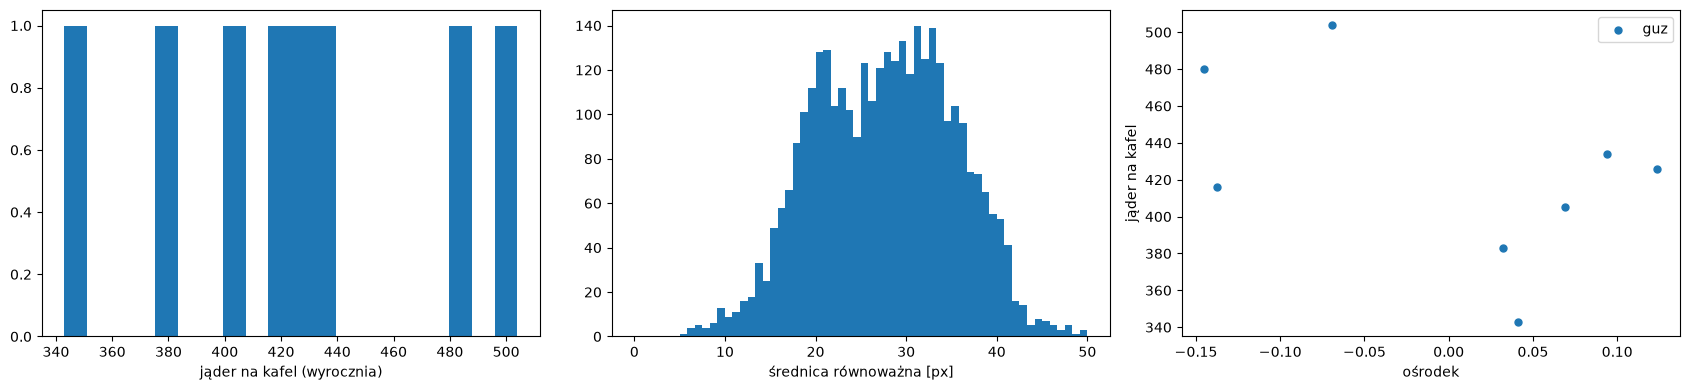

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(per_tile["n_nuclei"], bins=20)
ax[0].set_xlabel("jąder na kafel (wyrocznia)")
ax[1].hist(nuclei["equivalent_diameter_area"], bins=60, range=(0, 50))
ax[1].set_xlabel("średnica równoważna [px]")
for g, d in per_tile.groupby("group"):
    ax[2].scatter(d["center"] + np.random.default_rng(0).uniform(-0.15, 0.15, len(d)), d["n_nuclei"], label=g, s=25)
ax[2].set_xlabel("ośrodek")
ax[2].set_ylabel("jąder na kafel")
ax[2].legend()
plt.tight_layout()
fig.savefig(out_dir / f"oracle_stats_{MODE}.png", dpi=120)

## 4. B: niewytrenowany Cellpose-SAM

Encoder z oryginalnych wag SAM ViT-L, losowa głowica (seed 0), to samo `predict` i `EVAL_KWARGS` co dla A.
Spodziewamy się 0 wykrytych jąder, więc PQ względem wyroczni = 0. To punkt startowy studenta w I3.

In [8]:
student_init = build_student_init(seed=0, out_path=Settings().outputs_dir / "student_init" / "seed0.pth")
untrained = load_student(student_init, device)
preds_b = {name: predict(untrained, [c17.read_tile(t) for t in ids]) for name, ids in sets.items()}
n_b = {name: sum(len(np.unique(m)) - 1 for m in p) for name, p in preds_b.items()}
print("jąder wykrytych przez B:", n_b)

vs_oracle = pd.DataFrame({
    name: summarize(evaluate_all(masks[name], preds_b[name], sets[name])) for name in sets
}).T
vs_oracle.round(4)

2026-10-26 19:55:57,729 [models INFO] >>>> loading model /home/alehen0076/histopathology_pnw/outputs/student_init/seed0.pth



predict:   0%|          | 0/4 [00:00<?, ?it/s]

/home/alehen0076/histopathology_pnw/.venv/lib/python3.13/site-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),

predict:  25%|██▌       | 1/4 [01:14<03:44, 74.75s/it]


predict:  50%|█████     | 2/4 [02:30<02:30, 75.41s/it]


predict:  75%|███████▌  | 3/4 [03:45<01:15, 75.33s/it]

...


predict:  75%|███████▌  | 3/4 [03:45<01:15, 75.31s/it]


predict: 100%|██████████| 4/4 [05:01<00:00, 75.46s/it]


predict: 100%|██████████| 4/4 [05:01<00:00, 75.40s/it]

jąder wykrytych przez B: {'val': 0, 'test': 0}


,pq,sq,dq,pq@0.75,aji,ap@0.5,pq_pooled,n_images
val,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
test,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0


## 5. Samozgodność wyroczni (poprzeczka dla I3)

PQ między maską wyroczni a maską z lustrzanego odbicia kafla (odbitą z powrotem). Gdyby wyrocznia była idealnie
spójna, wyszłoby 1. Student uczony na jej maskach nie powinien być „zgodniejszy” z wyrocznią, niż ona sama ze sobą,
więc ta liczba jest naturalnym sufitem zgodności i bazą dla progu stopu w notebooku 03.

In [9]:
selfcons, selfcons_tables = {}, {}
for name, ids in sets.items():
    summary, table = al.oracle_self_consistency(oracle, ids, masks[name])
    selfcons[name], selfcons_tables[name] = summary, table
pd.DataFrame(selfcons).T.round(4)


predict:   0%|          | 0/4 [00:00<?, ?it/s]


predict:  25%|██▌       | 1/4 [01:15<03:47, 75.94s/it]


predict:  50%|█████     | 2/4 [02:32<02:32, 76.19s/it]


predict:  75%|███████▌  | 3/4 [03:48<01:16, 76.16s/it]


predict: 100%|██████████| 4/4 [05:05<00:00, 76.35s/it]

...


predict:  50%|█████     | 2/4 [02:33<02:34, 77.03s/it]


predict:  75%|███████▌  | 3/4 [03:56<01:19, 79.46s/it]


predict: 100%|██████████| 4/4 [05:18<00:00, 80.55s/it]


predict: 100%|██████████| 4/4 [05:18<00:00, 79.63s/it]

,pq,sq,dq,pq@0.75,aji,ap@0.5,pq_pooled,n_images
val,0.9453,0.9589,0.9858,0.9364,0.9559,0.9720,0.9467,4.0
test,0.9326,0.9510,0.9806,0.9245,0.9425,0.9619,0.9325,4.0


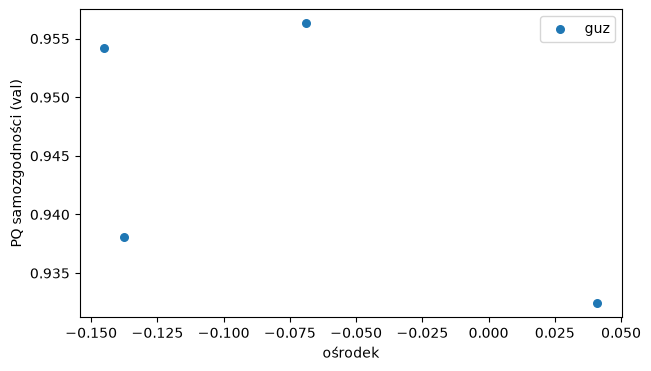

In [10]:
(out_dir / f"oracle_self_consistency_{MODE}.json").write_text(json.dumps(selfcons, indent=2, default=float))
pd.concat([t.assign(set=n) for n, t in selfcons_tables.items()]).to_csv(
    out_dir / f"oracle_self_consistency_per_tile_{MODE}.csv", index=False)

t = selfcons_tables["val"].merge(manifest[["tile_id", "center", "group"]], left_on="image_id", right_on="tile_id")
fig, ax = plt.subplots(figsize=(7, 4))
for g, d in t.groupby("group"):
    ax.scatter(d["center"] + np.random.default_rng(0).uniform(-0.15, 0.15, len(d)), d["pq"], label=g, s=30)
ax.set_xlabel("ośrodek")
ax.set_ylabel("PQ samozgodności (val)")
ax.legend()
fig.savefig(out_dir / f"self_consistency_by_center_{MODE}.png", dpi=120)

## 6. Wizualizacja: wyrocznia A vs niewytrenowany B

Po jednym kaflu „guz” i „normalna” z val, wycinek 300×300 px. Kontury: żółte = predykcja. Zwróć uwagę, czy A
nie pomija jąder (np. bardzo jasnych, rozmytych albo w obszarach z limfocytami) albo nie dzieli jednego jądra na kilka.

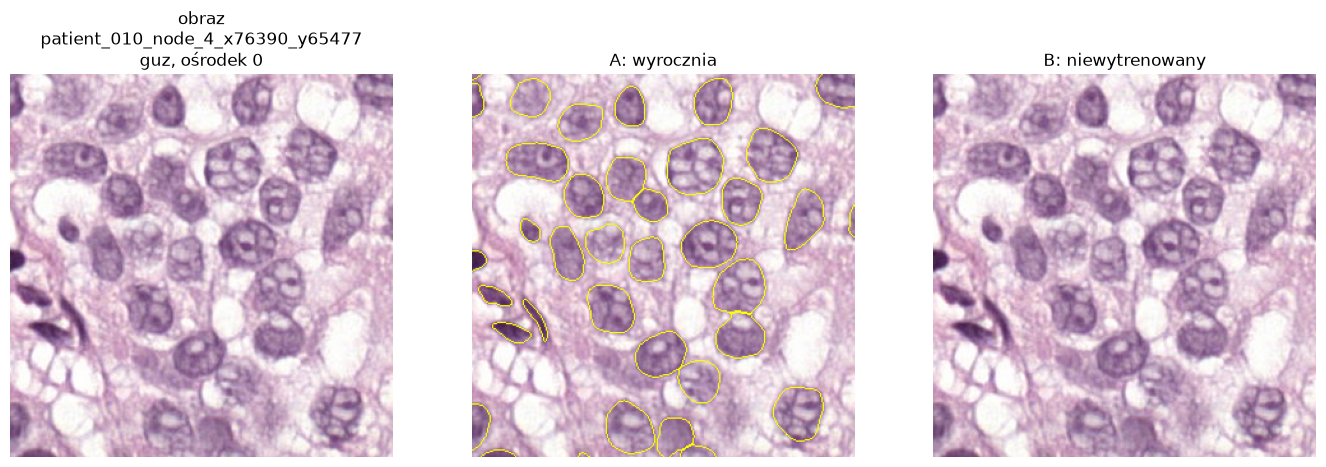

In [11]:
def contours(image, mask, color=(255, 255, 0)):
    out = image.copy()
    out[find_boundaries(mask, mode="inner")] = color
    return out


val_ids = sets["val"]
picks = []
for g in ("guz", "normalna"):
    cand = [t for t in val_ids if meta.loc[t, "group"] == g]
    if cand:
        picks.append(cand[0])
crop = np.s_[350:650, 350:650]
fig, ax = plt.subplots(len(picks), 3, figsize=(14, 4.6 * len(picks)), squeeze=False)
for row, tid in enumerate(picks):
    k = val_ids.index(tid)
    img = c17.read_tile(tid)[crop]
    panels = [(img, f"obraz\n{tid}\n{meta.loc[tid, 'group']}, ośrodek {meta.loc[tid, 'center']}"),
              (contours(img, masks["val"][k][crop]), "A: wyrocznia"),
              (contours(img, preds_b["val"][k][crop]), "B: niewytrenowany")]
    for col, (panel, title) in enumerate(panels):
        ax[row, col].imshow(panel)
        ax[row, col].set_title(title)
        ax[row, col].axis("off")
plt.tight_layout()
fig.savefig(out_dir / f"oracle_vs_untrained_{MODE}.png", dpi=120)

## Dyskusja

Liczb nie wpisuję, bo zależą od Twojego przebiegu (`MODE = "full"`). Uzupełnij po uruchomieniu:

| zbiór | samozgodność wyroczni (PQ) | B vs wyrocznia (PQ) | mediana jąder / kafel | mediana średnicy [px] |
|---|---|---|---|---|
| val | | | | |
| test | | | | |

### Na co patrzeć

- **B ≈ 0**: encoder SAM bez wytrenowanej głowicy nie daje sensownych flow fields, więc nie powstają maski.
  Cała wiedza o jądrach w studencie będzie pochodzić z kafli wybranych w AL.
- **Samozgodność < 1** to szum wyroczni (Cellpose nie jest równoważny względem odbić przy tym samym obrazie).
  Jeśli jest niska (np. < 0.7), a student w notebooku 03 jej nie przekracza, to nie jest wina studenta.
- **Guz vs normalna / ośrodki**: sprawdź, czy liczba jąder, rozmiar i samozgodność różnią się systematycznie między
  ośrodkami (barwienie, skaner). To podstawa do pytania, czy selektor AL w ogóle ma co wybierać.
- **Brak GT**: nie raportuj PQ względem wyroczni jako jakości segmentacji. Jedyny zewnętrzny pomiar jakości jest w
  notebooku 03 (student wytrenowany tu, oceniony na MoNuSeg względem prawdziwych masek).
- `oracle_self_consistency_<MODE>.json` zawiera poprzeczkę dla notebooka 03.